# Reading an L2A product with xarray

The L2A products of GRS are standard Zarr stores (or NetCDF files), readable with
[xarray](https://docs.xarray.dev) and [rioxarray](https://corteva.github.io/rioxarray) only. This
notebook opens the product written by the {doc}`processing tutorial <../processing>` and shows:

- the layout of a Zarr product: full resolution, overviews (pyramid) and ancillary data,
- the georeferencing and true-colour maps,
- the decoding of the `flags` bit field and the `mask` of the valid water pixels,
- the extraction of an area from longitude / latitude bounds, reading only the needed chunks,
- the spectra of a few pixels and the export of a subset to GeoTIFF.

## 1. Libraries

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # activates the .rio accessor
import zarr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pyproj import Transformer

warnings.filterwarnings('ignore', category=FutureWarning)
opj = os.path.join
print(f'xarray: {xr.__version__}, zarr: {zarr.__version__}')

xarray: 2026.9.0, zarr: 3.4.1


In [2]:
# settings: edit the path to run the notebook on your own product
product = ('/data/satellite/Sentinel-2/test/grs_tutorial/'
           'S2B_MSIL2AGRS_20200411T110619_T30TWT_tutorial.zarr')
odir = '/data/satellite/Sentinel-2/test/grs_tutorial'    # outputs of section 6

## 2. Layout of a Zarr product

| group | content |
|---|---|
| `0` | full resolution: `Rrs`, `BRDFg`, `aot550`, `wind`, `flags`, `mask`, angles, `dem` |
| `1`, `2`, ... | overviews, each 2 x coarser than the previous one (mean of the valid pixels; nearest for `flags` and `mask`) |
| `ancillary` | CAMS data and gaseous transmittance on the coarse CAMS grid (dimensions `xc`, `yc`) |

The root attribute `multiscales` describes the pyramid:

In [3]:
root = zarr.open_group(product, mode='r')
pd.DataFrame(root.attrs['multiscales'][0]['layout'])

,group,scale,shape
0,0,1,"[5490, 5490]"
1,1,2,"[2745, 2745]"
2,2,4,"[1373, 1373]"
3,3,8,"[687, 687]"
4,4,16,"[344, 344]"


In [4]:
l2a = xr.open_zarr(product, group='0')          # lazy: nothing is read yet
anc = xr.open_zarr(product, group='ancillary')
l2a

<xarray.Dataset> Size: 4GB
Dimensions:             (y: 5490, x: 5490, wl: 11)
Coordinates:
  * y                   (y) float64 44kB 5.3e+06 5.3e+06 ... 5.19e+06 5.19e+06
  * x                   (x) float64 44kB 5e+05 5e+05 ... 6.098e+05 6.098e+05
  * wl                  (wl) int64 88B 443 490 560 665 705 ... 842 865 1610 2190
    central_wavelength  (wl) float32 44B dask.array<chunksize=(11,), meta=np.ndarray>
    spatial_ref         int32 4B ...
    time                datetime64[ns] 8B ...
Data variables:
    aot550              (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    BRDFg               (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    dem                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    flags               (y, x) uint32 121MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    mask                (y, x) uint8 30MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    raa                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    Rrs                 (wl, y, x) float64 3GB dask.array<chunksize=(11, 256, 256), meta=np.ndarray>
    sza                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    vza                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    wind                (y, x) float64 241MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
Attributes: (12/79)
    path:                                /tmp/tmpz_iv6nmm/tmp_20200411T110619...
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/30TWT...
    product_name:                        S2B_MSIL1C_20200411T110619_N0500_R13...
    ...                                  ...
    hcld_threshold:                      0.003
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    GRSdriver_version:                   1.0.9
    metadata_profile:                    datacube

The variables are stored as scaled integers and decoded to floats by xarray. The attributes record
the processing settings and the metadata of the Level-1 image:

In [5]:
{key: l2a.attrs[key] for key in ('version', 'tile', 'opac_model', 'aot_resolution') if key in l2a.attrs}

{'version': '3.1.0',
 'tile': '30TWT',
 'opac_model': 'COAV_rh70',
 'aot_resolution': 240}

## 3. True-colour maps

The projection of the tile is read from the georeferencing (`spatial_ref`) to plot on cartopy maps.
An overview level is enough for a quick-look of the whole tile: level 2 is 16 x lighter than the full
resolution.

Text(0.5, 1.0, 'valid water pixels (mask == 0)')

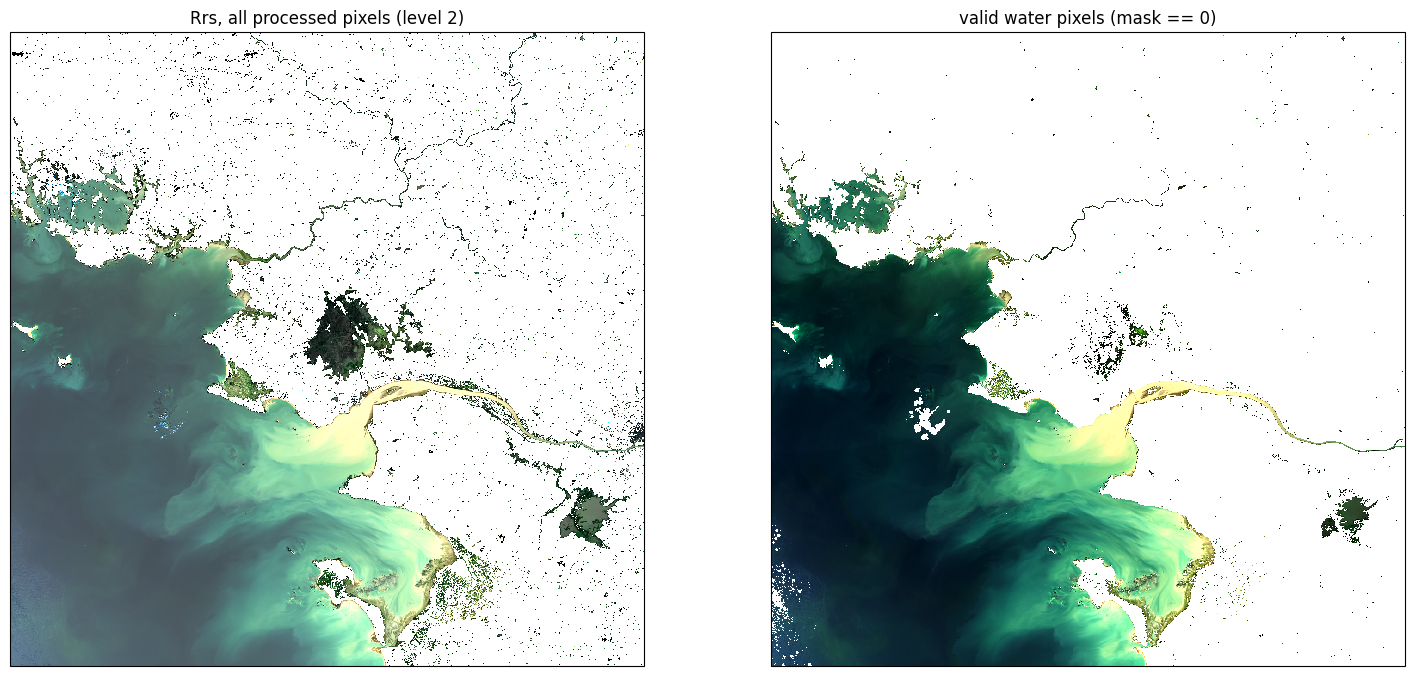

In [6]:
epsg = l2a.rio.crs.to_epsg()
proj = ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)

quicklook = xr.open_zarr(product, group='2')
fig, axs = plt.subplots(1, 2, figsize=(18, 9), subplot_kw={'projection': proj})
quicklook.Rrs.sel(wl=[665, 560, 490]).plot.imshow(rgb='wl', robust=True, ax=axs[0], transform=proj)
axs[0].set_title('Rrs, all processed pixels (level 2)')
quicklook.Rrs.sel(wl=[665, 560, 490]).where(quicklook.mask == 0).plot.imshow(
    rgb='wl', robust=True, ax=axs[1], transform=proj)
axs[1].set_title('valid water pixels (mask == 0)')

## 4. Flags and mask

`flags` is a bit field: bit $n$ is raised when the test $n$ is true. The names and descriptions of the
bits are stored in its attributes (see {doc}`../../api/mask`):

In [7]:
names = l2a.flags.attrs['flag_names']
descriptions = l2a.flags.attrs['flag_descriptions']
table = pd.DataFrame({'name': names, 'description': descriptions})
table = table[table.name != 'None']
table.index.name = 'bit'
table

,name,description
bit,,
0,nodata,nodata in input image
1,cloud_p06,low confidence cloud mask from s2cloudless wit...
2,cloud_p08,high confidence cloud mask from s2cloudless wi...
3,water_swir_visible_index,water mask from normalized index from swir and...
4,water_red_visible_index,water mask from normalized index from nir and ...
5,thin_cirrus,"thin cirrus mask from cirrus band, threshold 0..."
6,opac_cirrus,"opac cirrus mask from cirrus band, threshold 0..."
7,high_swir,"high swir (bright cloud, too bright reflection..."
8,surfwater_land,land mask from surfwater input file


To select the pixels where a flag is raised, test its bit with a bitwise *and*. The binary `mask`
(0: valid water pixel, 1: rejected) combines the main flags:

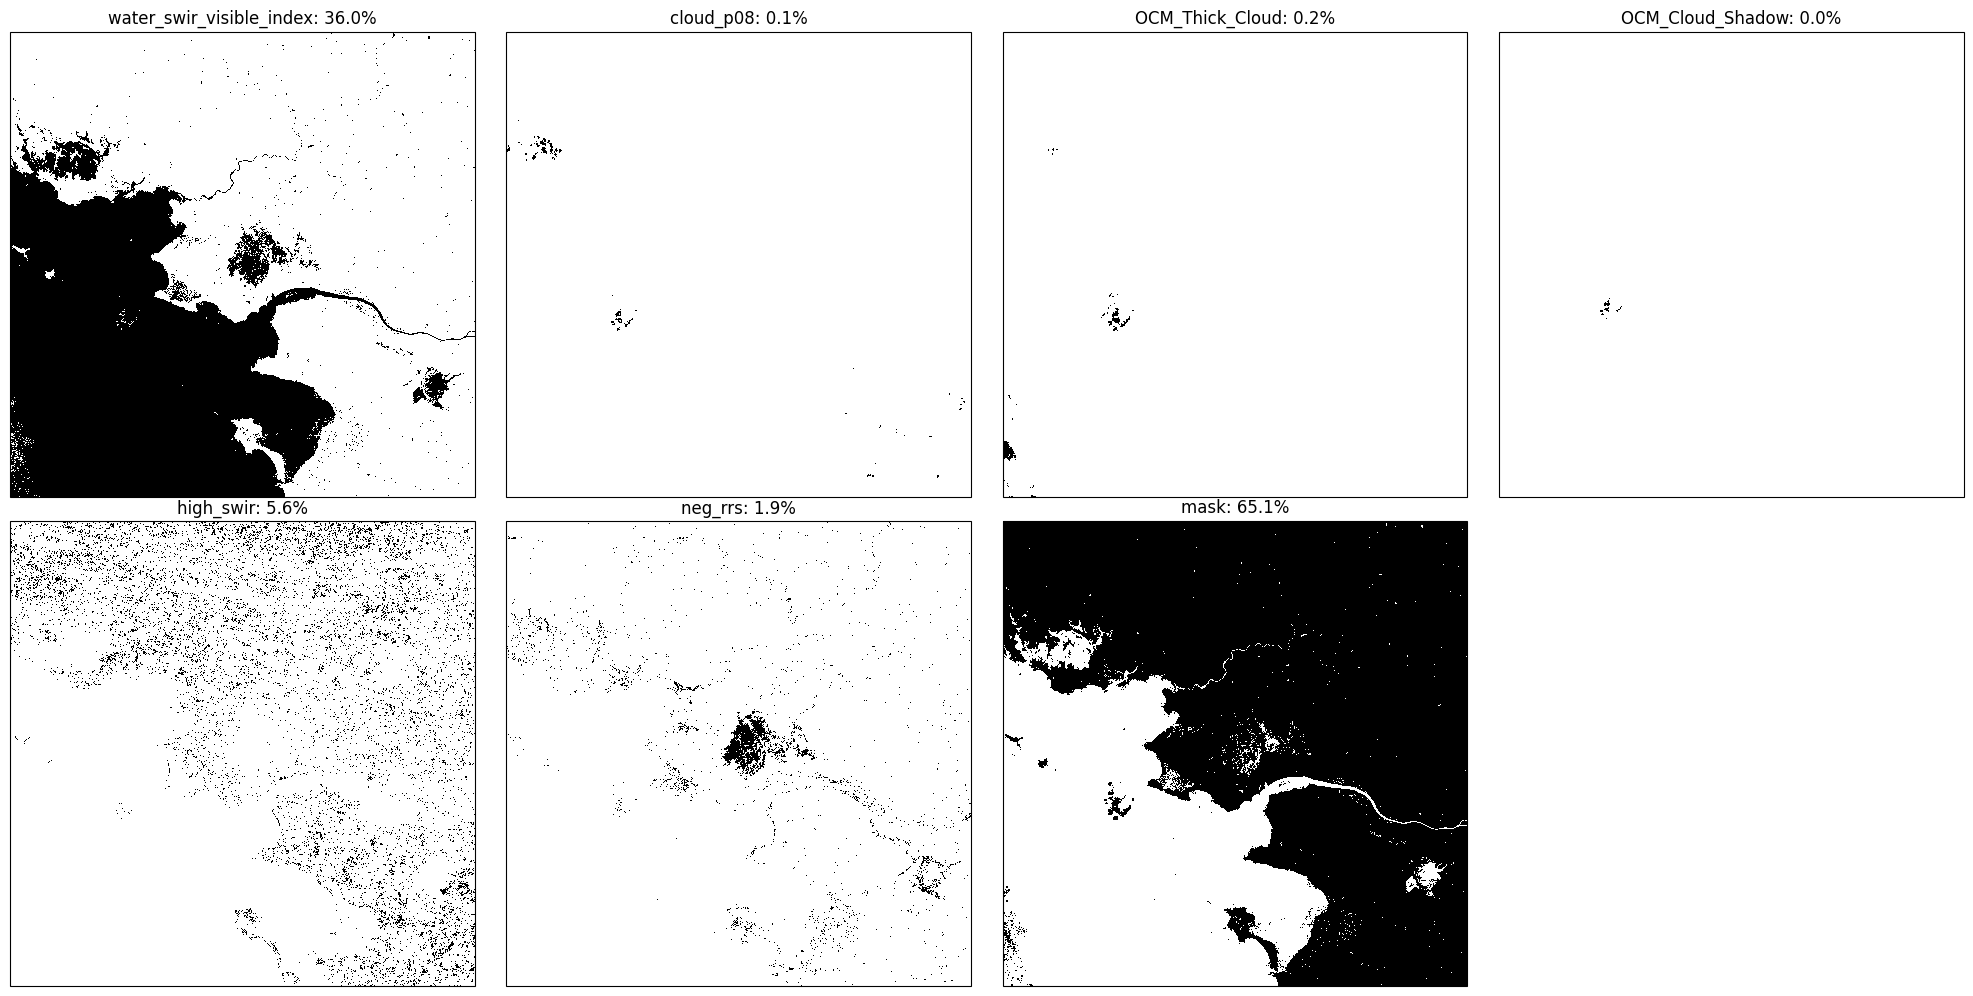

In [8]:
def flag(flags, name):
    """Boolean map of the flag `name`."""
    bit = list(flags.attrs['flag_names']).index(name)
    return (flags & (1 << bit)) > 0


flags = quicklook.flags.load()
selection = ['water_swir_visible_index', 'cloud_p08', 'OCM_Thick_Cloud', 'OCM_Cloud_Shadow', 'high_swir', 'neg_rrs']
selection = [name for name in selection if name in list(flags.attrs['flag_names'])]

fig, axs = plt.subplots(2, 4, figsize=(20, 10), subplot_kw={'projection': proj})
for ax, name in zip(axs.ravel(), selection + ['mask']):
    da = quicklook.mask if name == 'mask' else flag(flags, name)
    da.plot.imshow(ax=ax, transform=proj, add_colorbar=False, cmap='Greys')
    ax.set_title(f'{name}: {float(da.mean()):.1%}')
for ax in axs.ravel()[len(selection) + 1:]:
    ax.set_axis_off()
plt.tight_layout()

## 5. Area of interest from longitude / latitude bounds

Convert the bounds into the projected coordinates of the tile, then cut with `rio.clip_box`: the
result stays lazy and only the chunks of the area are read. Here, the Loire estuary
(Saint-Nazaire), with turbid waters inside the estuary and clearer waters offshore.

1693 x 1129 pixels


Text(0.5, 1.0, 'Rrs(665): turbidity of the Loire plume')

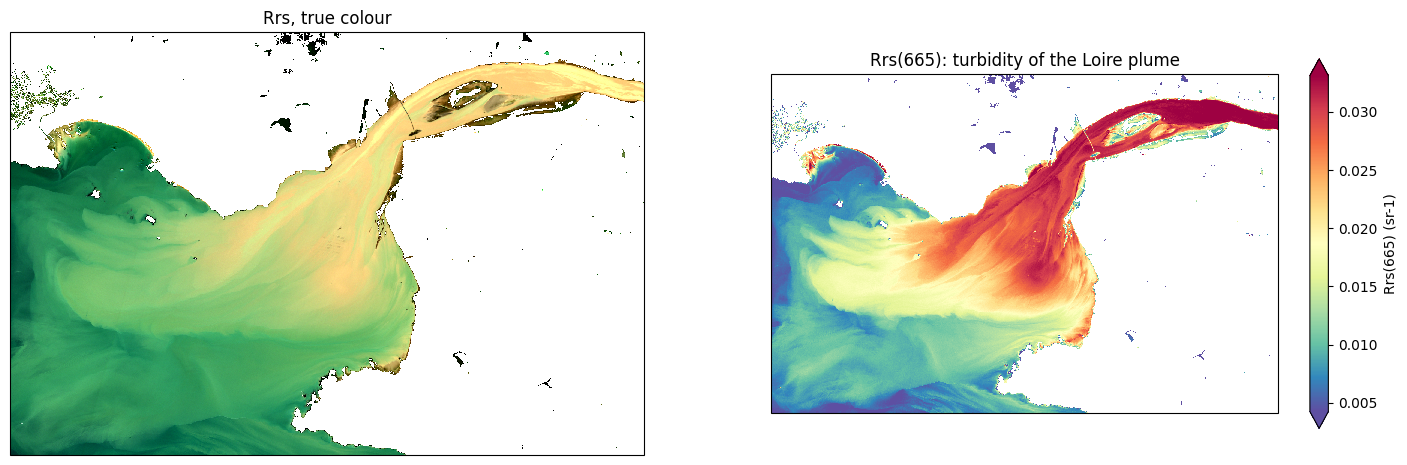

In [9]:
lonmin, lonmax, latmin, latmax = -2.45, -2.0, 47.12, 47.32

to_utm = Transformer.from_crs(4326, epsg, always_xy=True)
xmin, ymin = to_utm.transform(lonmin, latmin)
xmax, ymax = to_utm.transform(lonmax, latmax)

subset = l2a.rio.clip_box(minx=xmin, miny=ymin, maxx=xmax, maxy=ymax).load()
print(f"{subset.sizes['x']} x {subset.sizes['y']} pixels")

water = subset.mask == 0
fig, axs = plt.subplots(1, 2, figsize=(18, 8), subplot_kw={'projection': proj})
subset.Rrs.sel(wl=[665, 560, 490]).where(water).plot.imshow(rgb='wl', robust=True, ax=axs[0], transform=proj)
axs[0].set_title('Rrs, true colour')
subset.Rrs.sel(wl=665).where(water).plot.imshow(ax=axs[1], transform=proj, cmap='Spectral_r', robust=True,
                                               cbar_kwargs={'shrink': 0.6, 'label': 'Rrs(665) (sr-1)'})
axs[1].set_title('Rrs(665): turbidity of the Loire plume')

Spectra of a few pixels, from the estuary to the river plume (longitude, latitude):

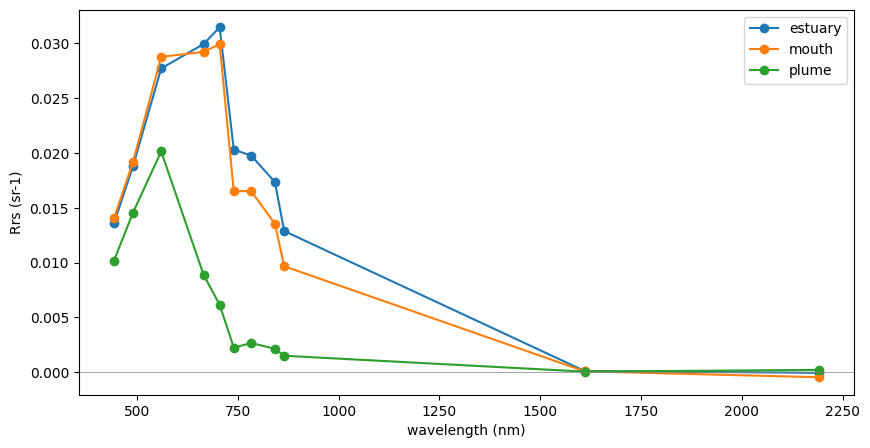

In [10]:
points = {'estuary': (-2.18, 47.27), 'mouth': (-2.25, 47.24), 'plume': (-2.4, 47.18)}

fig, ax = plt.subplots(figsize=(10, 5))
for name, (lon, lat) in points.items():
    x, y = to_utm.transform(lon, lat)
    pixel = subset.Rrs.where(water).sel(x=x, y=y, method='nearest')
    pixel.plot(ax=ax, marker='o', label=name)
ax.axhline(0, color='grey', lw=0.5)
ax.set(xlabel='wavelength (nm)', ylabel='Rrs (sr-1)', title='')
ax.legend()

## 6. Export

The subset can be written with the usual xarray / rioxarray functions, e.g. $R_{rs}$ as a multi-band
GeoTIFF for GIS software (to write subsets in the GRS format, see `grstbx.subset` in the
{doc}`grstbx tutorial <grstbx_l2a_visu>`).

In [11]:
os.makedirs(odir, exist_ok=True)
rrs = subset.Rrs.where(water).astype('float32')
rrs = rrs.assign_coords(band=('wl', [f'Rrs_{wl}' for wl in rrs.wl.values])).swap_dims(wl='band').drop_vars('wl')
tif = opj(odir, 'Rrs_loire_estuary.tif')
rrs.rio.to_raster(tif)
print(tif, xr.open_dataarray(tif, engine='rasterio').shape)

/data/satellite/Sentinel-2/test/grs_tutorial/Rrs_loire_estuary.tif (11, 1129, 1693)


## 7. NetCDF products

Products written in NetCDF (output path ending in `.nc`, or GRS 2.x products) are opened the same way,
with `xr.open_dataset`; the ancillary data are in the companion file `<name>_anc.nc`:

```python
l2a = xr.open_dataset('<name>.nc', chunks={})          # lazy, with dask
anc = xr.open_dataset('<name>_anc.nc')
```